In [73]:
import pandas as pd
import numpy as np
df = pd.read_csv("decision_tree.csv")

def gini_impurity(yes, no):
    tot = yes + no
    assert tot >= 1, "total cannot be zero"
    return 1 - (yes / tot)**2 - (no / tot)**2

def get_feature_type(data, feature_name):
    if data[feature_name].isin(["Yes", "No"]).all(): return "bool"
    elif pd.api.types.is_numeric_dtype(data[feature_name]): return "int"
    else: raise ValueError(f"Invalid feature: {feature_name}")

class Node:
    def __init__(self, feature, data, children):
        self.feature = feature
        self.children = children or {}
        self.is_leaf  = len(self.children) == 0
        self.data = data
        self.prediction = data[data.columns[-1]].mode().iloc[0]

class DecisionTree:
    def __init__(self, max_depth):
        self.max_depth = max_depth

    def partition_data(self, data, feature):
        condition = True
        threshold, name = feature["feature_threshold"], feature["feature_name"]
        if threshold is None: condition = data[name] == "Yes"
        else: condition = data[name] < threshold

        left_data = data[condition]
        right_data = data[~condition]

        return {
            "left_data": left_data,
            "right_data": right_data
        }

    def get_label_impurity(self, data):
        label = data.columns[-1]
        tot = len(data[label])
        yes = (data[label] == "Yes").sum()
        no = tot - yes
        return gini_impurity(yes, no)

    def is_label_equal(self, data, val, i):
        label = data.columns[-1]
        return "yes" if data[label].iloc[i] == val else "no"

    def visualize(self, root):
        from graphviz import Digraph
        graph = Digraph("Decision Tree")
        feature_name = root.feature["feature_name"]
        feature_threshold = root.feature["feature_threshold"]

        label = ""
        if feature_threshold is None:
            label = feature_name
        else:
            label = f"{feature_name} < {feature_threshold}"

        graph.node("0", label)

        id = 0
        def add_node(node, node_id):
            nonlocal id
            if node.is_leaf: return
            left = node.children["left_node"]
            right = node.children["right_node"]

            left_label, right_label = "", ""
            if left.is_leaf: left_label = f"Prediction: {left.prediction}"
            else:
                left_label = left.feature["feature_name"]
                if left.feature["feature_threshold"] is not None:
                    left_label += f" < {left.feature['feature_threshold']}"
            id += 1
            graph.node(str(id), str(left_label))
            graph.edge(node_id, str(id), label="Yes")
            add_node(left, str(id))

            if right.is_leaf: right_label = f"Prediction: {right.prediction}"
            else:
                right_label = right.feature["feature_name"]
                if right.feature["feature_threshold"] is not None:
                    right_label += f" < {right.feature['feature_threshold']}"
            id += 1
            graph.node(str(id), str(right_label))
            graph.edge(node_id, str(id), label="No")
            add_node(right, str(id))

        add_node(root, str(id))
        return graph

    def find_feature_impurity(self, feature_name, left, right, left_n, right_n, n):
        left_impurity = gini_impurity(left["yes"], left["no"])
        left_weight = left_n / n

        right_impurity = gini_impurity(right["yes"], right["no"])
        right_weight = right_n / n

        return (left_weight * left_impurity + right_weight * right_impurity)

    def find_bool_feature_impurity(self, data, feature_name):
        if data[feature_name].nunique() < 2: return None
        left = {"yes": 0, "no": 0}
        right = {"yes": 0, "no": 0}
        left_n, right_n = 0, 0

        for (i, entry) in enumerate(data[feature_name]):
            if entry == "Yes":
                left[self.is_label_equal(data, "Yes", i)] += 1
                left_n += 1
            else:
                right[self.is_label_equal(data, "Yes", i)] += 1
                right_n += 1

        n = len(data[feature_name])
        return {
            "feature_name": feature_name,
            "feature_impurity": self.find_feature_impurity(feature_name, left, right, left_n, right_n, n),
            "feature_threshold": None # boolean feature
        }

    def find_int_feature_impurity(self, data, feature_name):
        avgs = []
        vals = sorted(data[feature_name].unique())

        if len(vals) < 2: return None

        for i in range(1, len(vals)):
            # if i == 0: continue
            avg = (vals[i - 1] + vals[i]) / 2
            avgs.append(avg)

        feature_impurity = 1
        threshold = 0 # best avg

        for avg in avgs:
            left = {"yes": 0, "no": 0}
            right = {"yes": 0, "no": 0}
            left_n, right_n = 0, 0
            for (i, entry) in enumerate(data[feature_name]):
                if entry < avg:
                    left[self.is_label_equal(data, "Yes", i)] += 1
                    left_n += 1
                else:
                    right[self.is_label_equal(data, "Yes", i)] += 1
                    right_n += 1
            n = len(data[feature_name])
            new_impurity = self.find_feature_impurity(feature_name, left, right, left_n, right_n, n)
            if new_impurity < feature_impurity:
                feature_impurity = new_impurity
                threshold = avg

        return {
            "feature_name": feature_name,
            "feature_impurity": feature_impurity,
            "feature_threshold": threshold
        }

    def generate(self, data, depth):
        if self.get_label_impurity(data) == 0 or depth >= self.max_depth: return Node(None, data, {})
        features = []

        for feature_name in data.columns[:-1]:
            feature_type = get_feature_type(data, feature_name)
            result = None
            if feature_type == "bool":
                result = self.find_bool_feature_impurity(data, feature_name)
            else:
                result = self.find_int_feature_impurity(data, feature_name)
            if result is not None: features.append(result)

        # find best split
        min_feature_impurity = 1
        best_feature = None
        for feature in features:
            if feature["feature_impurity"] >= min_feature_impurity: continue
            best_feature = feature
            min_feature_impurity = best_feature["feature_impurity"]
        if best_feature == None or min_feature_impurity >= self.get_label_impurity(data): return Node(None, data, {})

        partitions = self.partition_data(data, best_feature)
        left_tree = self.generate(partitions["left_data"], depth + 1)
        right_tree = self.generate(partitions["right_data"], depth + 1)
        return Node(best_feature, data, {
            "left_node": left_tree,
            "right_node": right_tree
        })

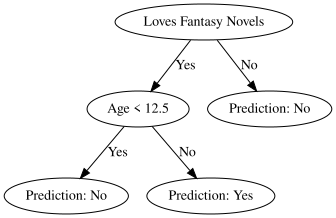

In [78]:
tree = DecisionTree(2)
root = tree.generate(df, 0)

tree.visualize(root)